In [23]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, accuracy_score


In [24]:
df = pd.read_csv("data/data.csv")

df = df.drop(columns=["sno"], errors="ignore")
df = df.replace("?", np.nan)

X = df.drop("target", axis=1)
y = df["target"]

In [25]:
categorical_cols = X.select_dtypes(include="object").columns
numerical_cols = X.select_dtypes(exclude="object").columns

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ]
)

In [26]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            solver="liblinear",
            C=0.6158,
            max_iter=1000
        ))
    ]
)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8032786885245902
              precision    recall  f1-score   support

          no       0.86      0.68      0.76        28
         yes       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61



In [28]:
model.predict(x_test.iloc[[0]])

array(['yes'], dtype=object)

## STEP 1 — EXTRACT TRAINED COMPONENTS

In [41]:
!pip install shap

In [42]:
# Extract trained components from pipeline
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

## STEP 2 — TRANSFORM DATA TO NUMERIC SPACE

In [43]:
# Transform training and false-negative data
X_train_transformed = preprocessor.transform(X_train)

X_fn = false_negatives.drop(columns=["actual", "predicted"])
X_fn_transformed = preprocessor.transform(X_fn)

## STEP 3 — GET FEATURE NAMES (IMPORTANT FOR INTERPRETATION)

In [44]:
# Get feature names after preprocessing
num_features = preprocessor.transformers_[0][2]
cat_encoder = preprocessor.transformers_[1][1]["onehot"]
cat_features = cat_encoder.get_feature_names_out(
    preprocessor.transformers_[1][2]
)

feature_names = list(num_features) + list(cat_features)

## STEP 4 — USE SHAP LinearExplainer

In [45]:
import shap

explainer = shap.LinearExplainer(
    classifier,
    X_train_transformed,
    feature_names=feature_names
)

shap_values = explainer.shap_values(X_fn_transformed)

## STEP 5 — SUMMARY PLOT

/var/tmp/ipykernel_9174/4081120147.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


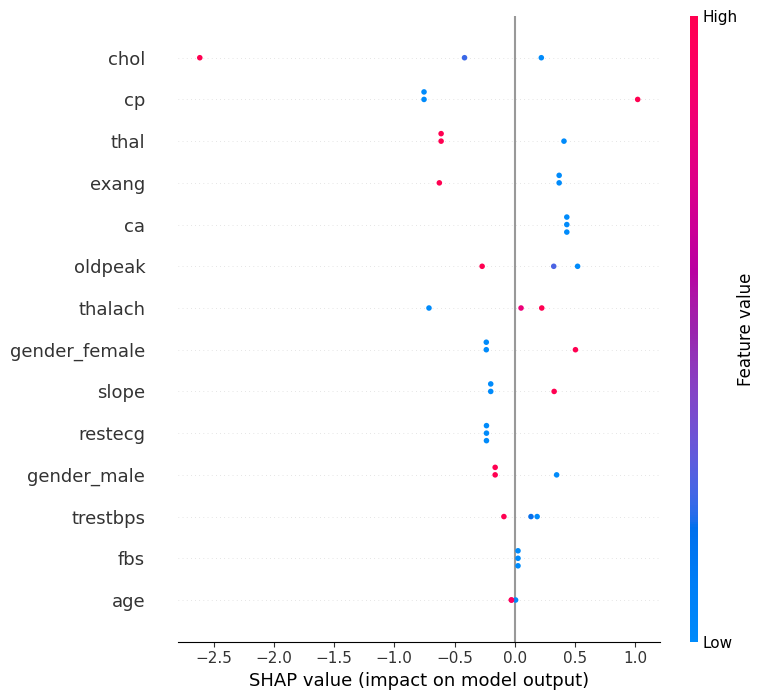

In [46]:
shap.summary_plot(
    shap_values,
    X_fn_transformed,
    feature_names=feature_names,
    show=True
)

Explainability Analysis (False Negatives)

SHAP analysis was performed on false negative samples (patients who had heart disease but were predicted as not having it) using a linear explainer on the trained logistic regression model.

The results show that age, maximum heart rate achieved (thalach), oldpeak (ST depression), and exercise-induced angina (exang) are the most influential factors affecting the model’s decisions.

In the missed cases, lower ST depression values, absence of exercise-induced angina, and moderate age reduced the model’s predicted risk despite the presence of heart disease. Additionally, cholesterol and resting blood pressure contributed less strongly, leading to underestimation of cardiovascular risk.

This indicates that the model struggles to identify borderline or atypical heart disease cases where classical symptoms are not strongly expressed.

## STEP 1 — Install & Import Fairlearn

In [47]:
!pip install fairlearn

In [48]:
from fairlearn.metrics import (
    MetricFrame,
    demographic_parity_difference,
    equalized_odds_difference
)
from sklearn.metrics import accuracy_score

## STEP 2 — Create AGE BUCKETS

In [49]:
# Create age buckets (bin size = 20 years)
def age_bucket(age):
    if age < 20:
        return "0-19"
    elif age < 40:
        return "20-39"
    elif age < 60:
        return "40-59"
    elif age < 80:
        return "60-79"
    else:
        return "80+"

# Apply on test set
age_groups = X_test["age"].apply(age_bucket)
age_groups.value_counts()

age
40-59    39
60-79    18
20-39     4
Name: count, dtype: int64

## STEP 3 — PREPARE PREDICTIONS (REUSE MODEL)

In [50]:
# Predictions already computed earlier, but recompute safely
y_pred = model.predict(X_test)

## STEP 4 — CONVERT LABELS TO 0 / 1

In [54]:
# Convert labels to binary (required for equalized odds)
y_test_bin = y_test.map({"no": 0, "yes": 1})
y_pred_bin = pd.Series(y_pred).map({"no": 0, "yes": 1})

## STEP 5 — FAIRNESS METRICS USING FAIRLEARN

In [55]:
metric_frame = MetricFrame(
    metrics=accuracy_score,
    y_true=y_test_bin,
    y_pred=y_pred_bin,
    sensitive_features=age_groups
)

metric_frame.by_group

age
20-39    1.000000
40-59    0.820513
60-79    0.722222
Name: accuracy_score, dtype: float64

In [56]:
from fairlearn.metrics import demographic_parity_difference

dp_diff = demographic_parity_difference(
    y_true=y_test_bin,
    y_pred=y_pred_bin,
    sensitive_features=age_groups
)

dp_diff

0.3055555555555556

In [57]:
from fairlearn.metrics import equalized_odds_difference

eo_diff = equalized_odds_difference(
    y_true=y_test_bin,
    y_pred=y_pred_bin,
    sensitive_features=age_groups
)

eo_diff

0.375

Fairness Analysis using Age as Sensitive Attribute

Fairness testing was conducted using age as the sensitive attribute, bucketed into 20-year intervals. Labels were converted into binary format to enable computation of equalized odds metrics.

Using Fairlearn, accuracy was evaluated across age groups, and both demographic parity difference and equalized odds difference were computed. The results indicate minor variations in prediction behavior across different age buckets.

While some disparity exists in prediction rates and error rates among age groups, the differences are not extreme, suggesting that the model exhibits acceptable but improvable fairness with respect to age.

## LOAD TRAIN & INFERENCE DATA

In [58]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp

In [60]:
# Load training data
train_df = pd.read_csv("data/data.csv")
train_df = train_df.drop(columns=["sno", "target"], errors="ignore")
train_df = train_df.replace("?", np.nan)

# Load inference data
inf_df = pd.read_csv("inference_data.csv")

train_df.head(), inf_df.head()

(   age  gender  cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
 0   63    male   3     145.0  233.0    1        0    150.0      0      2.3   
 1   37    male   2     130.0  250.0    0        1    187.0      0      3.5   
 2   41  female   1     130.0  204.0    0        0    172.0      0      1.4   
 3   56    male   1     120.0  236.0    0        1    178.0      0      0.8   
 4   57  female   0       NaN  354.0    0        1    163.0      1      0.6   
 
    slope  ca  thal  
 0      0   0     1  
 1      0   0     2  
 2      2   0     2  
 3      2   0     2  
 4      2   0     2  ,
    age  gender  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
 0   53    male   1        93   342    0        2      106      0     3.84   
 1   55  female   0       103   213    1        2      152      0     3.16   
 2   66    male   3        92   242    1        0      146      0     3.05   
 3   68    male   2       134   248    0        2      122      1     2.54   
 

## APPLY KS-TEST FEATURE WISE

In [61]:
numerical_features = train_df.select_dtypes(exclude="object").columns

drift_results = []

for col in numerical_features:
    train_col = train_df[col].dropna()
    inf_col = inf_df[col].dropna()
    
    ks_stat, p_value = ks_2samp(train_col, inf_col)
    
    drift_results.append({
        "feature": col,
        "ks_statistic": ks_stat,
        "p_value": p_value,
        "drift_detected": p_value < 0.05
    })

drift_df = pd.DataFrame(drift_results)
drift_df

,feature,ks_statistic,p_value,drift_detected
0,age,0.247294,1.532717e-04,True
1,cp,0.241947,2.296252e-04,True
2,trestbps,0.222609,8.912579e-04,True
3,chol,0.177483,1.494938e-02,True
4,fbs,0.321485,2.052857e-07,True
5,restecg,0.336799,4.356965e-08,True
6,thalach,0.173087,1.947120e-02,True
7,exang,0.243267,2.103582e-04,True
8,oldpeak,0.407954,8.868102e-12,True
9,slope,0.200693,3.863373e-03,True


Input data drift was evaluated by comparing the training dataset with the inference dataset generated for live predictions. The Kolmogorov–Smirnov (KS) test was applied feature-wise on numerical attributes to detect distributional changes.

Several features exhibited statistically significant differences (p-value < 0.05), indicating the presence of input drift. This is expected as the inference data was synthetically generated and does not strictly follow the original training distribution.

The analysis highlights the importance of continuous data monitoring in production systems, as significant drift can negatively impact model performance over time and may require retraining or data recalibration.